# Irradiaciones diarias, mensuales y anuales

Este cuaderno integra las series de irradiancia obtenidas con pvlib para calcular irradiaciones en diferentes escalas temporales. Se conserva la configuración del ejercicio anterior: Puebla, año 2026, separación de GHI mediante Erbs y transposición isotrópica de Liu y Jordan.

## 1. Irradiancia e irradiación

La **irradiancia** es una potencia por unidad de área y se expresa en $\mathrm{W/m^2}$. La **irradiación** es la energía recibida por unidad de área durante un intervalo:

$$H=\int G(t)\,dt$$

Para datos separados por un intervalo constante $\Delta t$:

$$H\approx\sum_i G_i\,\Delta t$$

En este ejercicio se emplean intervalos de 15 minutos. El factor de conversión a $\mathrm{kWh/m^2}$ es:

$$\frac{15}{60}\frac{1}{1000}=0.00025$$

In [49]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pvlib
from IPython.display import display
from pvlib import irradiance
from pvlib.location import Location

plt.style.use("seaborn-v0_8-whitegrid")
pd.options.display.float_format = lambda valor: f"{valor:,.3f}"

print("pvlib:", pvlib.__version__)

pvlib: 0.16.1


## 2. Sitio, periodo y plano receptor

El intervalo de 15 minutos reduce el error de integración respecto a una serie horaria. El año 2026 tiene 365 días, por lo que se esperan 35 040 registros.

In [50]:
latitude = 19.04
longitude = -98.20
altitude = 2160
timezone = "America/Mexico_City"
year = 2026
interval_minutes = 15

surface_tilt = 5.0
surface_azimuth = 180.0
albedo = 0.20

sitio = Location(
    latitude=latitude,
    longitude=longitude,
    tz=timezone,
    altitude=altitude,
    name="Puebla",
)

times = pd.date_range(
    start=f"{year}-01-01 00:00",
    end=f"{year + 1}-01-01 00:00",
    freq=f"{interval_minutes}min",
    tz=timezone,
    inclusive="left",
)

print(sitio)
print("Registros:", len(times))
print("Primer instante:", times[0])
print("Último instante:", times[-1])

Location: 
  name: Puebla
  latitude: 19.04
  longitude: -98.2
  altitude: 2160
  tz: America/Mexico_City
Registros: 35040
Primer instante: 2026-01-01 00:00:00-06:00
Último instante: 2026-12-31 23:45:00-06:00


## 3. Series de irradiancia

Ineichen proporciona la GHI de cielo claro utilizada como entrada reproducible. Erbs separa esa GHI en DNI y DHI. El modelo isotrópico calcula después las componentes sobre el plano inclinado. Estos resultados representan un escenario modelado de cielo claro, no una serie meteorológica medida ni un año climatológico típico.

In [51]:
solar_pos = sitio.get_solarposition(times)
cielo_claro = sitio.get_clearsky(
    times,
    model="ineichen",
    solar_position=solar_pos,
)

datos = solar_pos.join(cielo_claro[["ghi"]])

erbs = irradiance.erbs(
    ghi=datos["ghi"],
    zenith=datos["zenith"],
    datetime_or_doy=datos.index,
)

datos["dni_erbs"] = erbs["dni"].fillna(0).clip(lower=0)
datos["dhi_erbs"] = erbs["dhi"].fillna(0).clip(lower=0)
datos["cos_zenith"] = np.clip(
    np.cos(np.radians(datos["zenith"])),
    0,
    None,
)
datos["bhi_erbs"] = datos["dni_erbs"] * datos["cos_zenith"]

poa = irradiance.get_total_irradiance(
    surface_tilt=surface_tilt,
    surface_azimuth=surface_azimuth,
    solar_zenith=datos["zenith"],
    solar_azimuth=datos["azimuth"],
    dni=datos["dni_erbs"],
    ghi=datos["ghi"],
    dhi=datos["dhi_erbs"],
    albedo=albedo,
    model="isotropic",
)

datos = datos.join(poa)
display(
    datos[[
        "ghi",
        "bhi_erbs",
        "dhi_erbs",
        "poa_direct",
        "poa_sky_diffuse",
        "poa_ground_diffuse",
        "poa_global",
    ]].loc[f"{year}-03-20 12:00"]
)

ghi                  1,105.050
bhi_erbs               922.716
dhi_erbs               182.333
poa_direct             946.875
poa_sky_diffuse        181.986
poa_ground_diffuse       0.421
poa_global           1,129.282
Name: 2026-03-20 12:00:00-06:00, dtype: float64

## 4. Comprobación de balances

Antes de integrar se verifican las identidades:

$$GHI=BHI+DHI$$

$$POA_{global}=POA_{directa}+POA_{cielo}+POA_{suelo}$$

In [52]:
error_horizontal = (
    datos["ghi"]
    - datos["bhi_erbs"]
    - datos["dhi_erbs"]
).abs().max()

error_poa = (
    datos["poa_global"]
    - datos["poa_direct"]
    - datos["poa_sky_diffuse"]
    - datos["poa_ground_diffuse"]
).abs().max()

print(f"Error máximo del balance horizontal: {error_horizontal:.6f} W/m²")
print(f"Error máximo del balance POA: {error_poa:.6f} W/m²")

Error máximo del balance horizontal: 0.000000 W/m²
Error máximo del balance POA: 0.000000 W/m²


## 5. Irradiación diaria

Cada suma diaria se multiplica por la duración del intervalo y se divide entre 1000. El resultado se expresa en $\mathrm{kWh/m^2/día}$. Para evitar confusiones, la irradiación normal directa se transforma primero en su componente sobre el plano horizontal, BHI.

In [53]:
columnas_irradiancia = {
    "ghi": "H_GHI",
    "bhi_erbs": "H_BHI",
    "dhi_erbs": "H_DHI",
    "poa_global": "H_POA_global",
    "poa_direct": "H_POA_directa",
    "poa_sky_diffuse": "H_POA_cielo",
    "poa_ground_diffuse": "H_POA_suelo",
}

factor_kwh = interval_minutes / 60 / 1000
irradiacion_diaria = (
    datos[list(columnas_irradiancia)]
    .resample("D")
    .sum()
    .mul(factor_kwh)
    .rename(columns=columnas_irradiancia)
)
irradiacion_diaria.index.name = "fecha"

display(irradiacion_diaria.head())
print("Días calculados:", len(irradiacion_diaria))

,H_GHI,H_BHI,H_DHI,H_POA_global,H_POA_directa,H_POA_cielo,H_POA_suelo
fecha,,,,,,,
2026-01-01 00:00:00-06:00,5.840,4.755,1.085,6.268,5.183,1.083,0.002
2026-01-02 00:00:00-06:00,5.847,4.760,1.087,6.274,5.187,1.085,0.002
2026-01-03 00:00:00-06:00,5.855,4.766,1.089,6.281,5.192,1.087,0.002
2026-01-04 00:00:00-06:00,5.865,4.773,1.092,6.289,5.197,1.090,0.002
2026-01-05 00:00:00-06:00,5.875,4.780,1.095,6.298,5.203,1.093,0.002


Días calculados: 365


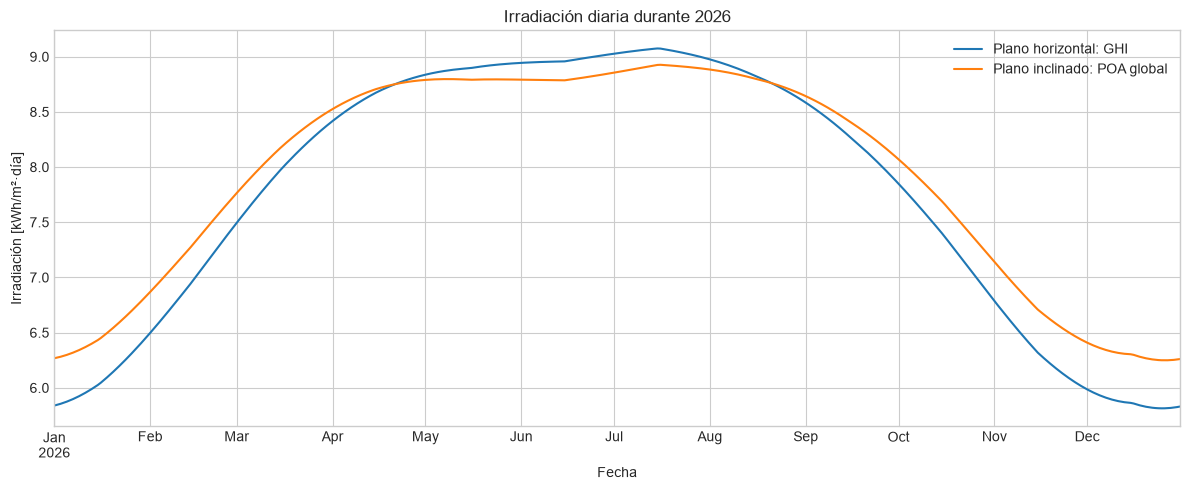

In [54]:
fig, ax = plt.subplots(figsize=(12, 5))
irradiacion_diaria[["H_GHI", "H_POA_global"]].plot(
    ax=ax,
    linewidth=1.5,
)
ax.set_title("Irradiación diaria durante 2026")
ax.set_xlabel("Fecha")
ax.set_ylabel("Irradiación [kWh/m²·día]")
ax.legend(["Plano horizontal: GHI", "Plano inclinado: POA global"])
fig.tight_layout()
plt.show()

## 6. Irradiación diaria media mensual

La media diaria mensual responde cuánto recibe, en promedio, un día de cada mes:

$$\overline{H}_{d,m}=\frac{1}{N_m}\sum_{d=1}^{N_m}H_d$$

La unidad permanece en $\mathrm{kWh/m^2/día}$.

In [55]:
media_diaria_mensual = irradiacion_diaria.resample("MS").mean()
media_diaria_mensual.index = [
    "Ene", "Feb", "Mar", "Abr", "May", "Jun",
    "Jul", "Ago", "Sep", "Oct", "Nov", "Dic",
]
media_diaria_mensual.index.name = "mes"

display(
    media_diaria_mensual[["H_GHI", "H_POA_global"]]
    .rename(columns={
        "H_GHI": "GHI media diaria",
        "H_POA_global": "POA media diaria",
    })
)

,GHI media diaria,POA media diaria
mes,,
Ene,6.088,6.492
Feb,6.969,7.295
Mar,7.980,8.174
Abr,8.660,8.691
May,8.898,8.794
Jun,8.973,8.804
Jul,9.042,8.900
Ago,8.811,8.789
Sep,8.256,8.394


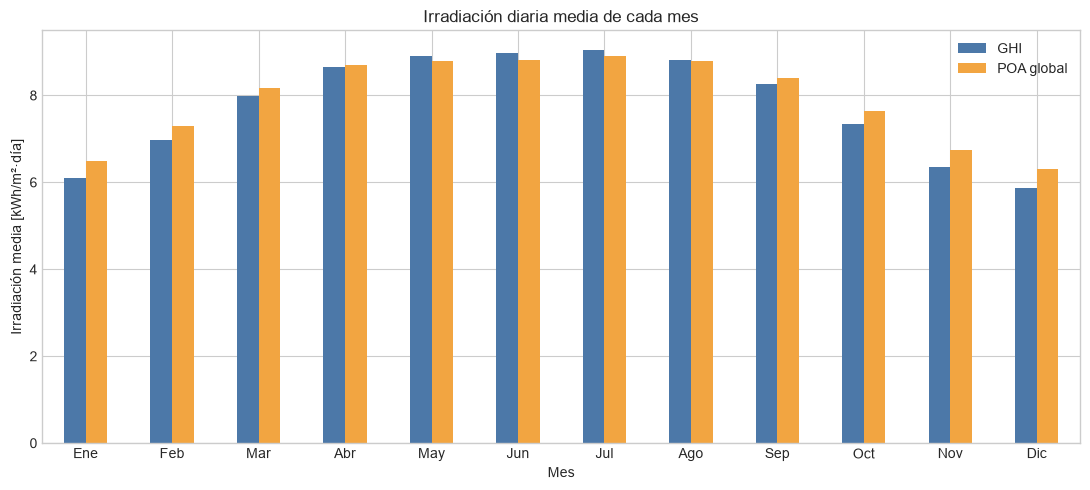

In [56]:
fig, ax = plt.subplots(figsize=(11, 5))
media_diaria_mensual[["H_GHI", "H_POA_global"]].plot.bar(
    ax=ax,
    color=["#4C78A8", "#F2A541"],
)
ax.set_title("Irradiación diaria media de cada mes")
ax.set_xlabel("Mes")
ax.set_ylabel("Irradiación media [kWh/m²·día]")
ax.legend(["GHI", "POA global"])
ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
plt.show()

## 7. Irradiación mensual acumulada

La acumulación mensual suma las irradiaciones de todos los días del mes:

$$H_m=\sum_{d=1}^{N_m}H_d$$

Se expresa en $\mathrm{kWh/m^2/mes}$. No debe confundirse con la media diaria mensual.

In [57]:
acumulada_mensual = irradiacion_diaria.resample("MS").sum()
acumulada_mensual.index = media_diaria_mensual.index
acumulada_mensual.index.name = "mes"

display(
    acumulada_mensual[["H_GHI", "H_POA_global"]]
    .rename(columns={
        "H_GHI": "GHI acumulada",
        "H_POA_global": "POA acumulada",
    })
)

,GHI acumulada,POA acumulada
mes,,
Ene,188.724,201.255
Feb,195.139,204.273
Mar,247.392,253.409
Abr,259.802,260.717
May,275.846,272.609
Jun,269.176,264.112
Jul,280.291,275.895
Ago,273.145,272.452
Sep,247.667,251.816


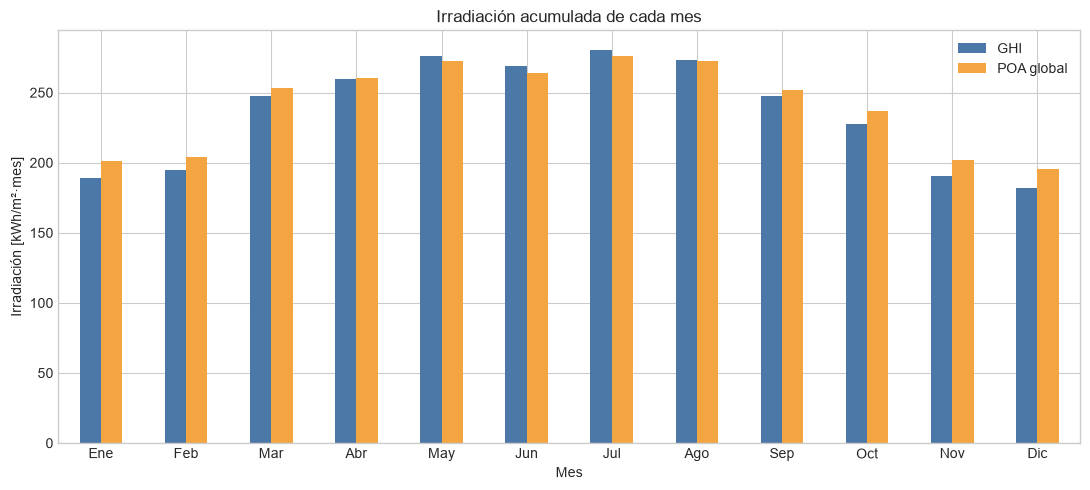

In [58]:
fig, ax = plt.subplots(figsize=(11, 5))
acumulada_mensual[["H_GHI", "H_POA_global"]].plot.bar(
    ax=ax,
    color=["#4C78A8", "#F2A541"],
)
ax.set_title("Irradiación acumulada de cada mes")
ax.set_xlabel("Mes")
ax.set_ylabel("Irradiación [kWh/m²·mes]")
ax.legend(["GHI", "POA global"])
ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
plt.show()

## 8. Irradiación anual acumulada y media diaria anual

La irradiación anual acumulada es:

$$H_{anual}=\sum_{d=1}^{365}H_d$$

La irradiación diaria media anual es:

$$\overline{H}_{d,anual}=\frac{H_{anual}}{365}$$

In [59]:
resumen_anual = pd.DataFrame({
    "Acumulada anual [kWh/m²·año]": irradiacion_diaria.sum(),
    "Media diaria anual [kWh/m²·día]": irradiacion_diaria.mean(),
})

nombres = {
    "H_GHI": "GHI horizontal",
    "H_BHI": "Directa horizontal BHI",
    "H_DHI": "Difusa horizontal DHI",
    "H_POA_global": "POA global",
    "H_POA_directa": "POA directa",
    "H_POA_cielo": "POA difusa del cielo",
    "H_POA_suelo": "POA reflejada por el suelo",
}
resumen_anual = resumen_anual.rename(index=nombres)
display(resumen_anual)

,Acumulada anual [kWh/m²·año],Media diaria anual [kWh/m²·día]
GHI horizontal,"2,837.241",7.773
Directa horizontal BHI,"2,325.998",6.373
Difusa horizontal DHI,511.244,1.401
POA global,"2,890.814",7.920
POA directa,"2,379.464",6.519
POA difusa del cielo,510.271,1.398
POA reflejada por el suelo,1.080,0.003


In [60]:
ghi_anual = resumen_anual.loc[
    "GHI horizontal",
    "Acumulada anual [kWh/m²·año]",
]
poa_anual = resumen_anual.loc[
    "POA global",
    "Acumulada anual [kWh/m²·año]",
]
ganancia_poa = 100 * (poa_anual / ghi_anual - 1)

balance_horizontal_anual = abs(
    resumen_anual.loc["GHI horizontal", "Acumulada anual [kWh/m²·año]"]
    - resumen_anual.loc["Directa horizontal BHI", "Acumulada anual [kWh/m²·año]"]
    - resumen_anual.loc["Difusa horizontal DHI", "Acumulada anual [kWh/m²·año]"]
)
balance_poa_anual = abs(
    resumen_anual.loc["POA global", "Acumulada anual [kWh/m²·año]"]
    - resumen_anual.loc["POA directa", "Acumulada anual [kWh/m²·año]"]
    - resumen_anual.loc["POA difusa del cielo", "Acumulada anual [kWh/m²·año]"]
    - resumen_anual.loc["POA reflejada por el suelo", "Acumulada anual [kWh/m²·año]"]
)

print(f"GHI anual acumulada: {ghi_anual:,.2f} kWh/m²·año")
print(f"POA anual acumulada: {poa_anual:,.2f} kWh/m²·año")
print(f"Diferencia relativa POA frente a GHI: {ganancia_poa:,.2f} %")
print(f"Error del balance horizontal anual: {balance_horizontal_anual:.6f} kWh/m²")
print(f"Error del balance POA anual: {balance_poa_anual:.6f} kWh/m²")

GHI anual acumulada: 2,837.24 kWh/m²·año
POA anual acumulada: 2,890.81 kWh/m²·año
Diferencia relativa POA frente a GHI: 1.89 %
Error del balance horizontal anual: 0.000000 kWh/m²
Error del balance POA anual: 0.000000 kWh/m²


## 9. Resumen de resultados

Las cantidades calculadas tienen significados diferentes:

- **Irradiación diaria:** energía recibida en una fecha específica, en $\mathrm{kWh/m^2/día}$.
- **Irradiación diaria media mensual:** energía de un día promedio del mes, en $\mathrm{kWh/m^2/día}$.
- **Irradiación mensual acumulada:** energía total del mes, en $\mathrm{kWh/m^2/mes}$.
- **Irradiación anual acumulada:** energía total del año, en $\mathrm{kWh/m^2/año}$.
- **Irradiación diaria media anual:** energía de un día promedio del año, en $\mathrm{kWh/m^2/día}$.

El análisis posterior de sombras deberá aplicarse a cada intervalo antes de efectuar estas sumas. Así se obtendrá una pérdida energética ponderada por irradiancia, en lugar de una simple fracción de posiciones solares bloqueadas.